# Regularization Technique

## 1. Import Necessary Libraries

In [8]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

## 2. Data Collection

In [9]:
house_data = fetch_california_housing()
house_data 

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [10]:
house_data_df = pd.DataFrame(house_data.data, columns = house_data.feature_names)
house_data_df["target"] = house_data.target
house_data_df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


## 3. Data Understanding

In [11]:
house_data_df.isna().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64

In [12]:
house_data_df.dtypes

MedInc        float64
HouseAge      float64
AveRooms      float64
AveBedrms     float64
Population    float64
AveOccup      float64
Latitude      float64
Longitude     float64
target        float64
dtype: object

## 4. Model Building

In [13]:
X = house_data_df.drop("target", axis = 1)
y = house_data_df["target"]
X = X.head(350)
y = y[:350]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2, random_state = 12, shuffle = True)

In [14]:
X_train.shape,X_test.shape

((280, 8), (70, 8))

## 5. Model Training // 6. Model Testing // 7. Model Evaluation

### Linear Regression

In [15]:
linear_model = LinearRegression()
linear_model.fit(X_train,y_train)
print("Linear Regression Coefficients")
print(linear_model.coef_)

Linear Regression Coefficients
[ 3.50030370e-01 -2.66888692e-03 -3.96725750e-02 -2.41696552e-01
  9.58112867e-05 -9.91464255e-02  1.05701558e+01  2.13844827e+00]


### Ridge Regression

In [16]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train,y_train)
print("Ridge Regression Coefficients")
print(ridge_model.coef_)

Ridge Regression Coefficients
[ 3.98612108e-01  9.64177267e-04 -3.59993415e-02 -2.31813643e-01
  9.99314154e-05 -2.17256230e-01  1.11478399e+00 -9.20041678e-01]


### Lasso Regression

In [39]:
lasso_model = Lasso(alpha = 0.1)
lasso_model.fit(X_train,y_train)
print("Lasso Regression Coefficients")
print(lasso_model.coef_)

Lasso Regression Coefficients
[ 3.58946783e-01  0.00000000e+00 -0.00000000e+00  0.00000000e+00
  1.00529766e-04 -9.02390553e-02  0.00000000e+00  0.00000000e+00]


### Elastic Net Regression

In [46]:
elastic_net_model = ElasticNet(alpha = 0.1)
elastic_net_model.fit(X_train,y_train)
print("Elastic Net Regression Coefficients")
print(elastic_net_model.coef_)

Elastic Net Regression Coefficients
[ 3.63923421e-01  4.77174426e-04 -0.00000000e+00 -0.00000000e+00
  1.02084331e-04 -1.60306935e-01  0.00000000e+00 -0.00000000e+00]


## Data Visualization

In [47]:
import matplotlib.pyplot as plt

def plot_coefficients(model, feature_names, title):
    
    coefficient_df = pd.DataFrame({"Feature": feature_names, "Coefficient": model.coef_ })

    coefficient_df = coefficient_df.sort_values(by = "Coefficient")
    print(coefficient_df)
        
    plt.figure(figsize=(6,4))
    plt.barh(coefficient_df["Feature"], coefficient_df["Coefficient"])
    
    plt.title(title)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Features")
    
    plt.tight_layout()
    plt.show()

### Linear Regression

      Feature  Coefficient
3   AveBedrms    -0.241697
5    AveOccup    -0.099146
2    AveRooms    -0.039673
1    HouseAge    -0.002669
4  Population     0.000096
0      MedInc     0.350030
7   Longitude     2.138448
6    Latitude    10.570156


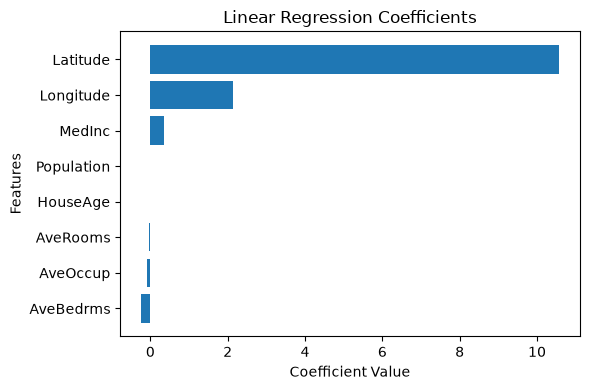

In [48]:
plot_coefficients(linear_model, X.columns, "Linear Regression Coefficients")

### Ridge Regression

      Feature  Coefficient
7   Longitude    -0.920042
3   AveBedrms    -0.231814
5    AveOccup    -0.217256
2    AveRooms    -0.035999
4  Population     0.000100
1    HouseAge     0.000964
0      MedInc     0.398612
6    Latitude     1.114784


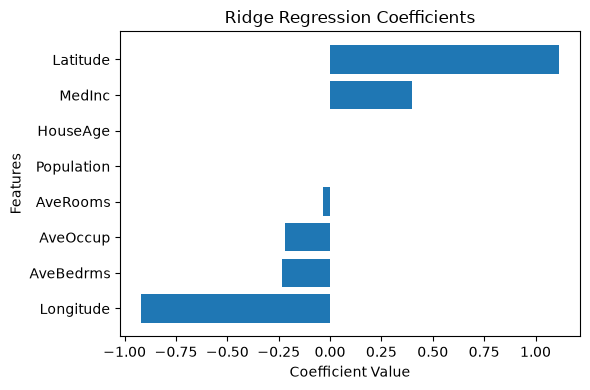

In [49]:
plot_coefficients(ridge_model, X.columns, "Ridge Regression Coefficients")

### Lasso Regression

      Feature  Coefficient
5    AveOccup    -0.090239
1    HouseAge     0.000000
3   AveBedrms     0.000000
2    AveRooms    -0.000000
7   Longitude     0.000000
6    Latitude     0.000000
4  Population     0.000101
0      MedInc     0.358947


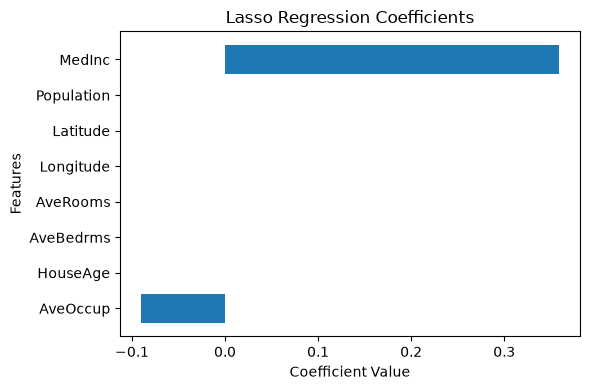

In [50]:
plot_coefficients(lasso_model, X.columns, "Lasso Regression Coefficients")

### ElasticNet Regression

      Feature  Coefficient
5    AveOccup    -0.160307
3   AveBedrms    -0.000000
6    Latitude     0.000000
2    AveRooms    -0.000000
7   Longitude    -0.000000
4  Population     0.000102
1    HouseAge     0.000477
0      MedInc     0.363923


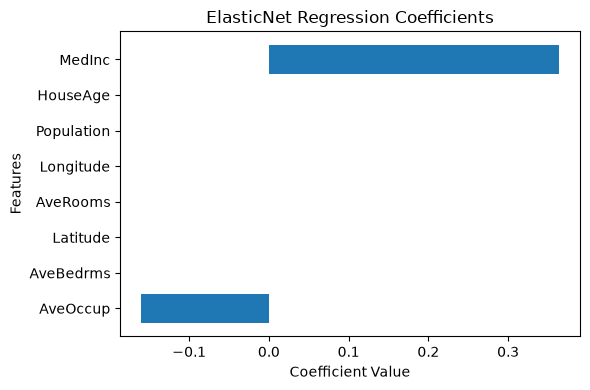

In [51]:
plot_coefficients(elastic_net_model, X.columns, "ElasticNet Regression Coefficients")